# Activity 3A — Solve equations and fit a trend

**COM7024 · Lesson 7 · SciPy**  
Real question: Can a simple mathematical line describe the long-term CO₂ trend? Suggested time: 20–25 minutes.

**How to use:** Run the cells from top to bottom. Every example works with the supplied full dataset.

## Step 0 — Find the data folder

This short setup supports your GitHub layout: `app/L7/` for notebooks and `data/` at the repository root.

In [1]:
from pathlib import Path

# The data folder is at the root of your GitHub repository.
DATA = Path("data")                 # If Jupyter starts at the repository root
if not DATA.exists():
    DATA = Path("../../data")       # If Jupyter starts inside app/L7
if not DATA.exists():
    DATA = Path("../data")          # If notebooks are in a separate folder

print("Data folder:", DATA.resolve())

Data folder: /workspaces/ProgrammongForDA/data


## 1. Solve two equations

Example: 2 coffees + 1 tea cost €8; 1 coffee + 2 teas cost €7.

In [2]:
import numpy as np
from scipy.linalg import solve

A = np.array([[2, 1], [1, 2]])
b = np.array([8, 7])
prices = solve(A, b)
print("Coffee price:", round(prices[0], 2))
print("Tea price:", round(prices[1], 2))

Coffee price: 3.0
Tea price: 2.0


## 2. Check the solution

Multiplying the matrix by the solution should give the original totals.

In [3]:
print("Check:", A @ prices)
print("Original totals:", b)

Check: [8. 7.]
Original totals: [8 7]


## 3. Load the full CO₂ dataset

Use all **observed** readings. Missing values are excluded from the fit.

In [4]:
import pandas as pd

df = pd.read_csv(DATA / "MaunaLoa_CO2_Full.csv", parse_dates=["date"])
print("Rows:", len(df))
print("Missing CO2 readings:", df["co2_ppm"].isna().sum())
display(df.head())

Rows: 2284
Missing CO2 readings: 59


,date,co2_ppm
0,1958-03-29,316.1
1,1958-04-05,317.3
2,1958-04-12,317.6
3,1958-04-19,317.5
4,1958-04-26,316.4


## 4. Prepare a straight-line model

We model **CO₂ = starting level + slope × years**.

In [5]:
observed = df.dropna(subset=["co2_ppm"]).copy()
observed["years"] = (observed["date"] - observed["date"].min()).dt.days / 365.25

x = observed["years"]
y = observed["co2_ppm"]

## 5. Find the best-fitting line

`lstsq` finds a least-squares solution when we have many observations, not just two equations.

In [6]:
from scipy.linalg import lstsq

A = np.column_stack([np.ones(len(x)), x])
starting_level, slope = lstsq(A, y)[0]
print("Starting level:", round(starting_level, 2), "ppm")
print("Average linear increase:", round(slope, 3), "ppm/year")

Starting level: 310.21 ppm
Average linear increase: 1.343 ppm/year


## 6. Plot observations and the fitted line

The line shows the overall trend, not the seasonal rises and falls.

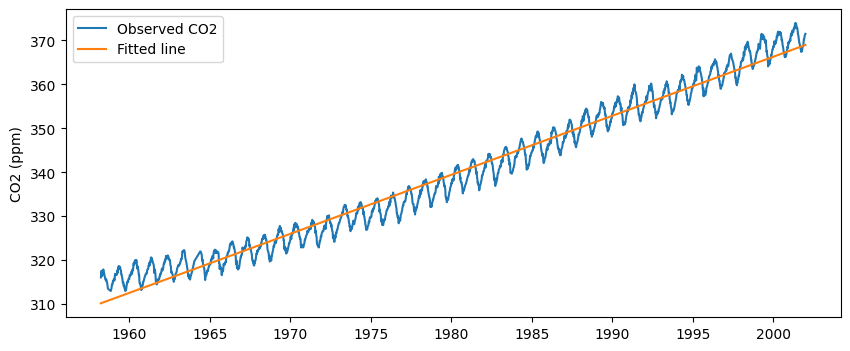

In [7]:
import matplotlib.pyplot as plt

observed["prediction"] = starting_level + slope * x
plt.figure(figsize=(10, 4))
plt.plot(observed["date"], y, label="Observed CO2")
plt.plot(observed["date"], observed["prediction"], label="Fitted line")
plt.ylabel("CO2 (ppm)")
plt.legend()
plt.show()

## Your turn — Quick challenge

Calculate the difference between each observed reading and the predicted value. What is the **mean absolute error (MAE)** in ppm?

### Before you finish

**Interpretation:** The fitted slope describes this historical dataset, not a guaranteed future rate. The model is deliberately simple and does not capture the seasonal cycle.